# Análisis PM2.5: pronóstico y perfiles diarios.

Vamos a trabajar con las mediciones por hora de Pekín desde el 2010 hasta el 2014. Queremos ver que formas se repiten a lo largo del día, en qué meses aparecen y que condiciones meteorológicas acompañan. Después, queremos saber con cuánto margen podemos anticipar el PM2.5.

## Preprocesado

In [2]:
from pathlib import Path

import pandas as pd

data_path = Path("data") / "dataset.csv"
data = pd.read_csv(data_path, na_values=["NA"])

date_columns = ["year", "month", "day", "hour"]
data["timestamp"] = (
    pd.to_datetime(data[date_columns], errors="raise")
    .dt.tz_localize("Asia/Shanghai")
)

data = data.sort_values("timestamp").reset_index(drop=True)

display(data[["timestamp", "pm2.5", "TEMP", "cbwd"]].head())

,timestamp,pm2.5,TEMP,cbwd
0,2010-01-01 00:00:00+08:00,NaN,-11.0,NW
1,2010-01-01 01:00:00+08:00,NaN,-12.0,NW
2,2010-01-01 02:00:00+08:00,NaN,-11.0,NW
3,2010-01-01 03:00:00+08:00,NaN,-14.0,NW
4,2010-01-01 04:00:00+08:00,NaN,-12.0,NW


Cargamos el CSV, convertimos NA en NaN, y juntamos año, mes, día y hora en fecha_hora, que indica que son horas locales de Pekín. 

Conservamos los ceros de PM2.5 y dejamos como ausentas las lecturas que faltan. Marcamos como ausente el valor de rocío (DEWP) que superé la tempertura, porque no tenemos un valor corregido confirmado. Empezamos el análisis en el primer día que tenga una medición, ya que como podemos ver los primero días no la tienen.

In [4]:
analysis_data = data.set_index("timestamp").asfreq("h").drop(columns="No")

invalid_dew_point = analysis_data["DEWP"] > analysis_data["TEMP"]
analysis_data.loc[invalid_dew_point, "DEWP"] = pd.NA

first_observed_hour = analysis_data["pm2.5"].first_valid_index()
analysis_start = first_observed_hour.normalize()
analysis_data = analysis_data.loc[analysis_start:].copy()

print(f"Fecha de inicio: {analysis_data.index[0]:%Y-%m-%d}")

Fecha de inicio: 2010-01-02


## PAA

Para ver como cambia el PM2.5 a lo largo del día, nos quedamos con los días que tengan las 24 lecturas y resumimos cada uno en seis medias de cuatro horas, empleando PAA para ello. Así podremos identificar en qué parte del día suele subir o bajar la contaminación.

In [5]:
daily_pm25 = (
    analysis_data.assign(
        date=analysis_data.index.date,
        hour=analysis_data.index.hour,
    )
    .pivot(index="date", columns="hour", values="pm2.5")
    .reindex(columns=range(24))
)

complete_days = daily_pm25.dropna()

paa_profiles = pd.DataFrame({
    f"{start:02d}-{start + 3:02d}": (
        complete_days.loc[:, start:start + 3].mean(axis=1)
    )
    for start in range(0, 24, 4)
})

print(f"Días completos: {len(complete_days)}")
print(f"Días fuera del agrupamiento: {len(daily_pm25) - len(complete_days)}")
display(paa_profiles.head())

Días completos: 1571
Días fuera del agrupamiento: 254


,00-03,04-07,08-11,12-15,16-19,20-23
date,,,,,,
2010-01-02,154.25,119.00,136.00,156.00,160.50,150.00
2010-01-03,68.25,81.25,86.00,97.00,67.50,73.00
2010-01-04,47.00,25.75,26.25,29.50,28.50,31.00
2010-01-05,29.00,27.50,30.50,35.00,56.25,76.50
2010-01-06,56.75,25.25,31.25,40.25,69.75,115.25


## K-means

Ahora agrupamos los perfiles, usando para ello k-means. Dos días pueden tener una evolución parecida, aunque uno tenga concentraciones más altas todo el día. Para poder comparar la forma de los perfiles, restamos las seis franjas con su media y dividimos por su desviación típica. 

In [6]:
daily_level = paa_profiles.mean(axis=1)
daily_spread = paa_profiles.std(axis=1)

has_shape = daily_spread.gt(0)

shape_profiles = (
    paa_profiles.loc[has_shape]
    .sub(daily_level.loc[has_shape], axis=0)
    .div(daily_spread.loc[has_shape], axis=0)
)

print(f"Días disponibles para agrupar por forma: {len(shape_profiles)}")
display(shape_profiles.head().round(2))

Días disponibles para agrupar por forma: 1571


,00-03,04-07,08-11,12-15,16-19,20-23
date,,,,,,
2010-01-02,0.53,-1.72,-0.64,0.64,0.93,0.26
2010-01-03,-0.92,0.21,0.62,1.58,-0.99,-0.51
2010-01-04,1.98,-0.70,-0.64,-0.23,-0.36,-0.04
2010-01-05,-0.68,-0.76,-0.61,-0.38,0.70,1.72
2010-01-06,0.01,-0.94,-0.76,-0.49,0.40,1.77


Ahora es más fácil ver en qué franjas sube o baja respecto a su nivel habitual diario. Ahora usamos k-means para ver qué formas se repiten en el conjunto de los días.

,silhouette,Inercia
k,,
2,0.377,4362.555
3,0.351,3395.452
4,0.279,2882.542
5,0.255,2560.564
6,0.261,2333.387
7,0.252,2132.781
8,0.258,1997.677


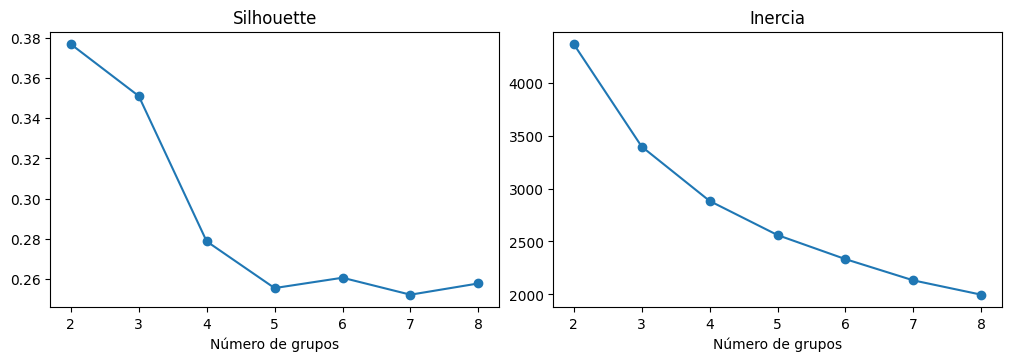

In [7]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

kmeans_models = {}
cluster_results = []

for k in range(2, 9):
    model = KMeans(n_clusters=k, n_init=20, random_state=42)
    labels = model.fit_predict(shape_profiles)

    kmeans_models[k] = model
    cluster_results.append({
        "k": k,
        "silhouette": silhouette_score(shape_profiles, labels),
        "inertia": model.inertia_,
    })

cluster_metrics = pd.DataFrame(cluster_results).set_index("k")

display(cluster_metrics.rename(columns={"inertia": "Inercia"}).round(3))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), layout="constrained")

cluster_metrics["silhouette"].plot(ax=axes[0], marker="o", title="Silhouette")
cluster_metrics["inertia"].plot(ax=axes[1], marker="o", title="Inercia")

for ax in axes:
    ax.set_xlabel("Número de grupos")

plt.show()

Para cada k, guardamos el modelo y los resultados, basándonos en el silhouette score, que mide cuanto de parecido es cada punto a su cluster, y diferente es el mismo punto de los demás, y la inercia, que mide cuanto se alejan los perfiles del centro de su grupo.

Vemos que con dos grupos tenemos mejor silhouette, pero con tres baja poco, y con cuatro ya cae más. Si lo complementamos con el gráfico de la inercia, vemos que el codo está en k = 3, por lo que debido a que la diferencia de silhouette no es tanta, nos quedamos con k = 3.

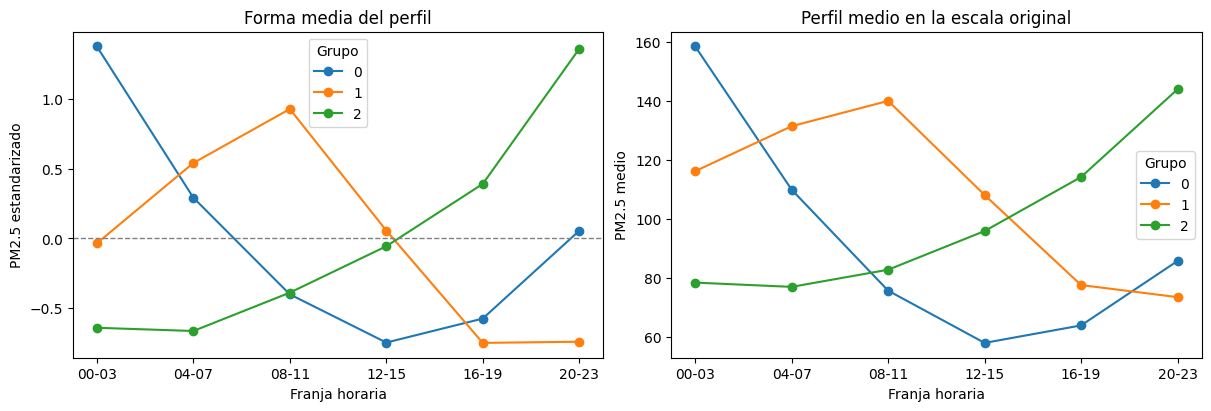

,Días,Nivel diario mediano
Grupo,,
0,482,69.04
1,367,92.75
2,722,76.54


In [8]:
chosen_k = 3

cluster_labels = pd.Series(
    kmeans_models[chosen_k].labels_,
    index=shape_profiles.index,
    name="group",
)

mean_shapes = shape_profiles.groupby(cluster_labels).mean()
mean_profiles = paa_profiles.loc[cluster_labels.index].groupby(cluster_labels).mean()

fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")

mean_shapes.T.plot(ax=axes[0], marker="o", title="Forma media del perfil")
axes[0].axhline(0, color="gray", linestyle="--", linewidth=1)
axes[0].set_ylabel("PM2.5 estandarizado")

mean_profiles.T.plot(ax=axes[1], marker="o", title="Perfil medio en la escala original")
axes[1].set_ylabel("PM2.5 medio")

for ax in axes:
    ax.set_xlabel("Franja horaria")
    ax.set_xticks(range(len(paa_profiles.columns)), paa_profiles.columns)
    ax.legend(title="Grupo")

plt.show()

group_summary = pd.DataFrame({
    "Días": cluster_labels.value_counts().sort_index(),
    "Nivel diario mediano": daily_level.groupby(cluster_labels).median(),
})

display(group_summary.rename_axis("Grupo").round(2))

Vemos que los tres perfiles evolucionan  de una forma distinta a lo largo del día. El grupo 0 empieza con su máximo en la madrugada, baja hasta el mediodía y vuelve a subir. El grupo 1 alcanza su máximo entre las 8 y las 12, y después baja. El grupo 2, el más frecuente, aumenta durante la tarda y alcanza su máximo al final del día. 

El grupo con el pico en la mañana tiene el nivel diario mñas alto. Aun así, el grupo 0 tiene la media de concentración más alta en la mañana. Mirar el nivel diario y la forma nos permiten que días suelen tener más contaminación y en que momento se concentran.

Ahora vamos a ver si esas tres formas aparecen igual durante todo el año. Calculamos por mes qué porcentaje de los días pertenece a cada perfil, tomando en cuenta la proporción de días usados.

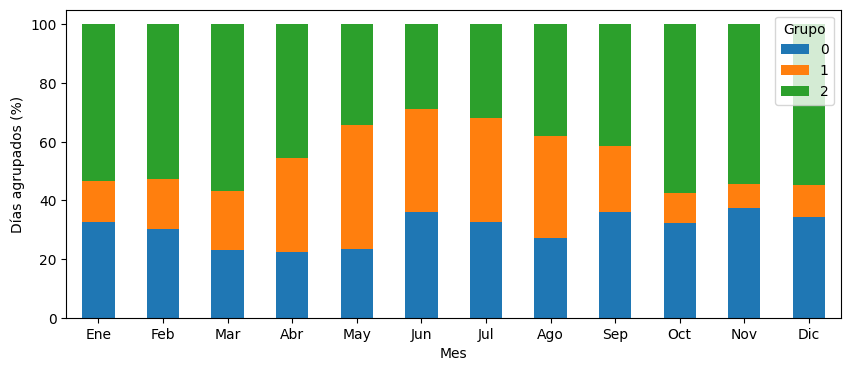

,Días agrupados,Días en el periodo,Cobertura (%)
Mes,,,
Ene,135,154,87.7
Feb,135,141,95.7
Mar,130,155,83.9
Abr,121,150,80.7
May,137,155,88.4
Jun,122,150,81.3
Jul,138,155,89.0
Ago,118,155,76.1
Sep,128,150,85.3


In [9]:
month_names = {
    1: "Ene", 2: "Feb", 3: "Mar", 4: "Abr",
    5: "May", 6: "Jun", 7: "Jul", 8: "Ago",
    9: "Sep", 10: "Oct", 11: "Nov", 12: "Dic",
}

daily_groups = cluster_labels.to_frame()
daily_groups["month"] = pd.to_datetime(daily_groups.index).month

monthly_counts = pd.crosstab(daily_groups["month"], daily_groups["group"])
grouped_days = monthly_counts.sum(axis=1)
monthly_shares = monthly_counts.div(grouped_days, axis=0).mul(100)

ax = monthly_shares.rename(index=month_names).plot.bar(
    stacked=True, figsize=(10, 4), rot=0
)
ax.set(xlabel="Mes", ylabel="Días agrupados (%)")
ax.legend(title="Grupo")
plt.show()

total_days = pd.Index(pd.to_datetime(daily_pm25.index).month).value_counts()
monthly_coverage = pd.DataFrame({
    "Días agrupados": grouped_days,
    "Días en el periodo": total_days,
    "Cobertura (%)": 100 * grouped_days / total_days,
}).sort_index()

display(monthly_coverage.rename(index=month_names).rename_axis("Mes").round(1))

El grupo de subida por la tarde (2) es más frecuente entre octubre y marzo. El pico de mañana (1) surge más entre abril y agosto. El que empieza con concentraciones altas en la madrugada y baja al medio día, aparece durante todo el año (3)

Como no hemos usado la cobertura completa, comprobamos si los días que dejamos fuera tenían concentraciones distintas.

In [10]:
day_coverage = pd.DataFrame({
    "observed_hours": daily_pm25.notna().sum(axis=1),
    "mean_pm25": daily_pm25.mean(axis=1),
    "month": pd.to_datetime(daily_pm25.index).month,
})

day_coverage["status"] = day_coverage["observed_hours"].eq(24).map({
    True: "Completo",
    False: "Incompleto",
})

days_with_readings = day_coverage.loc[day_coverage["observed_hours"].gt(0)]

print(f"Días sin ninguna lectura: {day_coverage['observed_hours'].eq(0).sum()}")

comparison_labels = {
    "size": "Días comparados",
    "median": "Mediana de la media diaria",
}

overall_comparison = (
    days_with_readings.groupby("status")["mean_pm25"]
    .agg(["size", "median"])
)

monthly_comparison = (
    days_with_readings.groupby(["month", "status"])["mean_pm25"]
    .agg(["size", "median"])
    .unstack("status")
)

display(overall_comparison.rename(columns=comparison_labels).round(2))
display(
    monthly_comparison.rename(index=month_names, columns=comparison_labels, level=0)
    .rename_axis("Mes")
    .round(2)
)

Días sin ninguna lectura: 36


,Días comparados,Mediana de la media diaria
status,,
Completo,1571,78.42
Incompleto,218,83.98


Días comparados            Mediana de la media diaria           
status        Completo Incompleto                   Completo Incompleto
Mes                                                                    
Ene                135         13                      71.67     118.39
Feb                135          6                      94.50     162.25
Mar                130         22                      69.94      96.77
Abr                121         28                      74.46      65.33
May                137         17                      71.04      88.95
Jun                122         26                      88.79      82.59
Jul                138         16                      91.10      60.13
Ago                118         30                      71.69     100.62
Sep                128         15                      75.10      55.48
Oct                136         16                      86.77      94.16
Nov                134         15                      77.67      78.13
Dic                137         14                      74.75      41.98

Al juntar todos los meses, el PM2.5 diario típico es de 78,42 en los días completos y de 83,98 en los incompletos con alguna lectura. Al separar por meses, las diferencias cambian. En agosto, por ejemplo, los días incompletos tienen un valor típico de 100,62 frente a 71,69 en los completos. En julio ocurre al revés.

Esto importa porque agosto es el mes en el que menos días pudimos agrupar. Los días que quedaron fuera tenían valores más altos en las horas que sí se midieron, así que los perfiles agrupados podrían representar peor una parte de ese mes. Además, hubo 36 días sin ninguna lectura. Con esta comparación podemos ver diferencias entre los días disponibles, pero sigue sin saberse qué pasó durante las horas que faltan.

Ahora vamos a ver que condiciones meteorológicas acompañan a cada forma.

In [11]:
daily_weather = (
    analysis_data.assign(date=analysis_data.index.date)
    .groupby("date")
    .agg(
        mean_temperature=("TEMP", "mean"),
        mean_dew_point=("DEWP", "mean"),
        mean_pressure=("PRES", "mean"),
        median_wind_accumulation=("Iws", "median"),
        northwest_pct=("cbwd", lambda wind: 100 * wind.eq("NW").mean()),
    )
    .join(cluster_labels, how="inner")
)

weather_by_group = daily_weather.groupby("group").median()

display(
    weather_by_group.rename(columns={
        "mean_temperature": "Temperatura media diaria (°C)",
        "mean_dew_point": "Punto de rocío medio diario (°C)",
        "mean_pressure": "Presión media diaria (hPa)",
        "median_wind_accumulation": "Mediana diaria de Iws",
        "northwest_pct": "Horas con viento NW en un día típico (%)",
    })
    .rename_axis("Grupo")
    .round(2)
)

,Temperatura media diaria (°C),Punto de rocío medio diario (°C),Presión media diaria (hPa),Mediana diaria de Iws,Horas con viento NW en un día típico (%)
Grupo,,,,,
0,13.81,0.60,1016.77,6.48,37.5
1,21.08,9.75,1011.17,5.59,12.5
2,8.73,-2.60,1019.46,4.47,25.0


En el grupo 0, el PM2.5 empieza alto de madrugada y va bajando hasta el mediodía. En esos días también vemos que el acumulado del viento es mayor y que hay más horas con viento del noroeste. Una posible explicación de la bajada es que el viento ayude a dispersar las partículas.

Los días del grupo 1, que tienen el pico por la mañana, suelen ser más cálidos y tienen un punto de rocío más alto. En el grupo 2, en cambio, los días suelen ser más fríos y el acumulado del viento es menor. Como cada grupo aparece más en unos meses que en otros, vamos a comparar los días dentro del mismo mes para ver si estas diferencias se mantienen.

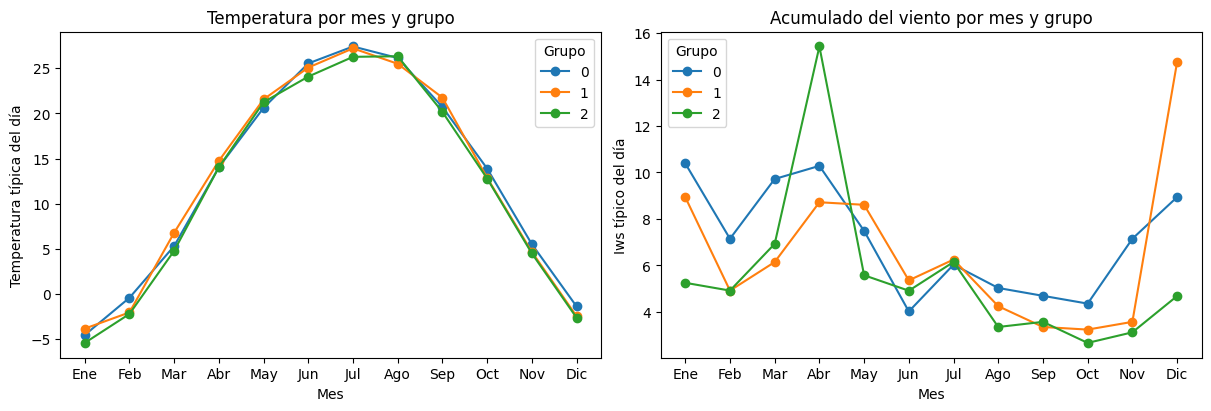

In [12]:
weather_with_month = daily_weather.assign(
    month=pd.to_datetime(daily_weather.index).month
)

monthly_weather = (
    weather_with_month.groupby(["month", "group"])[
        ["mean_temperature", "median_wind_accumulation"]
    ]
    .median()
    .unstack("group")
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")

monthly_weather["mean_temperature"].rename(index=month_names).plot(
    ax=axes[0], marker="o", title="Temperatura por mes y grupo"
)
axes[0].set_ylabel("Temperatura típica del día")

monthly_weather["median_wind_accumulation"].rename(index=month_names).plot(
    ax=axes[1], marker="o", title="Acumulado del viento por mes y grupo"
)
axes[1].set_ylabel("Iws típico del día")

for ax in axes:
    ax.set_xlabel("Mes")
    ax.set_xticks(range(len(month_names)), list(month_names.values()))
    ax.legend(title="Grupo")

plt.show()

Cuando comparamos los días del mismo mes, las temperaturas de los tres grupos se parecen bastante. En la tabla general, el grupo 2 parecía mucho más frío. Ahora vemos que buena parte de esa diferencia puede explicarse porque ese perfil aparece más en los meses fríos.

Con el acumulado del viento, el patrón cambia más según el mes. El grupo 2 suele tener valores bajos en meses como enero, agosto y octubre, pero en abril tiene el valor más alto de los tres grupos. Así que la subida de PM2.5 por la tarde coincide con un menor acumulado del viento en algunos meses. La relación no se mantiene igual durante todo el año.

## ARIMA y SARIMA

In [13]:
pm25 = analysis_data["pm2.5"]

validation_start = pd.Timestamp("2013-01-01", tz=pm25.index.tz)
test_start = pd.Timestamp("2014-01-01", tz=pm25.index.tz)

train_pm25 = pm25.loc[pm25.index < validation_start]
validation_pm25 = pm25.loc[
    (pm25.index >= validation_start) & (pm25.index < test_start)
]
test_pm25 = pm25.loc[pm25.index >= test_start]

forecast_horizons = (1, 6, 24)

print(f"Ajuste (2010–2012): {train_pm25.count()} lecturas observadas")
print(f"Validación (2013): {validation_pm25.count()} lecturas observadas")
print(f"Prueba (2014): {test_pm25.count()} lecturas observadas")

Ajuste (2010–2012): 24418 lecturas observadas
Validación (2013): 8678 lecturas observadas
Prueba (2014): 8661 lecturas observadas


Tramo continuo usado para la PACF: 1330 horas


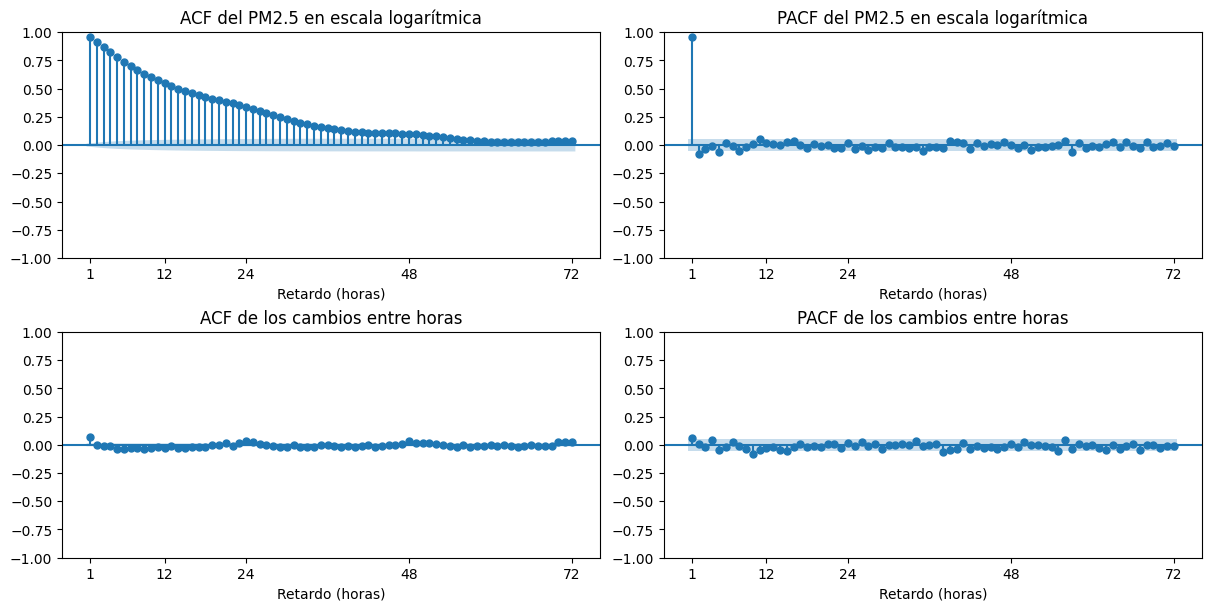

In [16]:
import numpy as np
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

train_log_pm25 = np.log1p(train_pm25)
train_log_changes = train_log_pm25.diff()

observed = train_log_pm25.notna()
run_ids = observed.ne(observed.shift()).cumsum()
longest_run = run_ids.loc[observed].value_counts().idxmax()
continuous_log_pm25 = train_log_pm25.loc[run_ids.eq(longest_run)]

print(f"Tramo continuo usado para la PACF: {len(continuous_log_pm25)} horas")

fig, axes = plt.subplots(2, 2, figsize=(12, 6), layout="constrained")

plot_acf(
    train_log_pm25, lags=72, zero=False, missing="conservative",
    ax=axes[0, 0], title="ACF del PM2.5 en escala logarítmica",
)
plot_pacf(
    continuous_log_pm25, lags=72, zero=False, method="ywm",
    ax=axes[0, 1], title="PACF del PM2.5 en escala logarítmica",
)
plot_acf(
    train_log_changes, lags=72, zero=False, missing="conservative",
    ax=axes[1, 0], title="ACF de los cambios entre horas",
)
plot_pacf(
    continuous_log_pm25.diff().iloc[1:], lags=72, zero=False, method="ywm",
    ax=axes[1, 1], title="PACF de los cambios entre horas",
)

for ax in axes.flat:
    ax.set(xlabel="Retardo (horas)", xticks=[1, 12, 24, 48, 72])

plt.show()

En los gráficos de arriba vemos que el PM2.5 se parece mucho al de la hora anterior. La ACF empieza cerca de 0,96 y va bajando poco a poco. En la PACF destaca sobre todo la primera hora. Esto nos da una razón para probar un AR(1), que usa el valor de la hora anterior.

Al mirar los cambios entre horas, en los gráficos de abajo, las correlaciones quedan mucho más cerca de cero. Por eso también tiene sentido probar un ARIMA que trabaje con esos cambios. En las 24, 48 y 72 horas no se ven picos claros. Aun así, probaremos un SARIMA con un ciclo de 24 horas para comprobar si ese patrón diario ayuda a pronosticar mejor en la validación.

Para pronosticar a 1, 6 o 24 horas repetimos la ultima lectura disponible a la hora de hacer el pronostico. Calculamos el MAE en 2013 y despues usamos las mismas horas para evaluar tanto ARIMA como SARIMA.

In [17]:
validation_history = pd.concat([train_pm25, validation_pm25])
last_observed = validation_history.ffill()
observed_validation_hours = validation_pm25.dropna().index

validation_hours = {}
persistence_validation = {}
persistence_results = []

for horizon in forecast_horizons:
    first_target = train_pm25.index[-1] + pd.Timedelta(hours=horizon)
    target_hours = observed_validation_hours[
        observed_validation_hours >= first_target
    ]

    predictions = last_observed.shift(horizon).loc[target_hours]
    actual = validation_pm25.loc[target_hours]
    mae = (predictions - actual).abs().mean()

    validation_hours[horizon] = target_hours
    persistence_validation[horizon] = predictions
    persistence_results.append({
        "Horizonte (horas)": horizon,
        "Horas evaluadas": len(target_hours),
        "MAE de persistencia": mae,
    })

persistence_summary = pd.DataFrame(persistence_results)
display(persistence_summary.set_index("Horizonte (horas)").round(2))

,Horas evaluadas,MAE de persistencia
Horizonte (horas),,
1,8678,13.21
6,8673,42.59
24,8655,75.95


A una hora, repetir la última lectura disponible da un MAE de 13,21. El error sube a 42,59 cuando pronosticamos a 6 horas y a 75,95 cuando pronosticamos a 24 horas. Esto tiene sentido con lo que vimos en la ACF: la lectura más reciente se parece mucho a la de la siguiente hora, pero se parece menos a lo que mediremos más adelante.

Estos resultados nos sirven de referencia. Para saber si ARIMA o SARIMA aportan algo, compararemos su error con el de persistencia en cada horizonte y sobre las mismas horas.

In [18]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

model_specs = {
    "AR(1)": {
        "order": (1, 0, 0),
        "trend": "c",
    },
    "ARIMA(0,1,1)": {
        "order": (0, 1, 1),
        "trend": "n",
    },
    "SARIMA(0,1,1)(1,0,0,24)": {
        "order": (0, 1, 1),
        "seasonal_order": (1, 0, 0, 24),
        "trend": "n",
    },
}

fitted_models = {}

for name, spec in model_specs.items():
    print(f"Ajustando {name}...")
    fitted_models[name] = SARIMAX(train_log_pm25, **spec).fit(disp=False)

print("Ajuste terminado.")

Ajustando AR(1)...
Ajustando ARIMA(0,1,1)...
Ajustando SARIMA(0,1,1)(1,0,0,24)...
Ajuste terminado.


El AR(1) usa el PM2.5 de la hora anterior. El ARIMA(0,1,1) mira cuánto cambia de una hora a otra y usa el último error para ajustar el pronóstico. El SARIMA hace lo mismo y además tiene en cuenta el cambio que hubo a la misma hora del día anterior.

In [19]:
def rolling_forecasts(fitted_model, observed_log, horizons):
    values = np.full((len(observed_log), len(horizons)), np.nan)
    max_horizon = max(horizons)
    model = fitted_model

    for position in range(len(observed_log)):
        steps = min(max_horizon, len(observed_log) - position)
        forecast = model.get_forecast(steps=steps).predicted_mean.to_numpy()

        for column, horizon in enumerate(horizons):
            if horizon <= steps:
                target_position = position + horizon - 1
                values[target_position, column] = forecast[horizon - 1]

        if position + 1 < len(observed_log):
            model = model.extend(observed_log.iloc[position:position + 1])

    return pd.DataFrame(
        np.expm1(values), index=observed_log.index, columns=horizons
    ).clip(lower=0)


validation_log = np.log1p(validation_pm25).asfreq("h")
validation_predictions = {"Persistencia": pd.DataFrame(persistence_validation)}

for name, fitted_model in fitted_models.items():
    print(f"Calculando los pronósticos de {name}...")
    validation_predictions[name] = rolling_forecasts(
        fitted_model, validation_log, forecast_horizons
    )

validation_results = []

for name, forecasts in validation_predictions.items():
    for horizon, target_hours in validation_hours.items():
        predictions = forecasts.loc[target_hours, horizon]
        actual = validation_pm25.loc[target_hours]

        if not np.isfinite(predictions).all():
            raise ValueError(f"Faltan pronósticos válidos de {name} a {horizon} horas.")

        validation_results.append({
            "Modelo": name,
            "Horizonte (horas)": horizon,
            "MAE": (predictions - actual).abs().mean(),
        })

validation_mae = pd.DataFrame(validation_results).pivot(
    index="Horizonte (horas)", columns="Modelo", values="MAE"
)

display(validation_mae.round(2))

Calculando los pronósticos de AR(1)...
Calculando los pronósticos de ARIMA(0,1,1)...
Calculando los pronósticos de SARIMA(0,1,1)(1,0,0,24)...


Modelo,AR(1),"ARIMA(0,1,1)",Persistencia,"SARIMA(0,1,1)(1,0,0,24)"
Horizonte (horas),,,,
1,14.03,13.04,13.21,13.04
6,43.08,42.54,42.59,42.51
24,65.36,76.00,75.95,76.73


A una hora, ARIMA y SARIMA obtienen el mismo MAE al redondear, 13,04, frente a 13,21 de persistencia. A seis horas, SARIMA tiene el error más bajo, pero la diferencia es pequeña: 42,51 frente a 42,59 de persistencia. En estos dos horizontes, añadir el ciclo diario apenas cambia el resultado.

La diferencia más clara aparece a 24 horas. El AR(1) consigue un MAE de 65,36 frente a 75,95 de persistencia, una mejora de alrededor del 14 %. Una posible explicación es que, cuanto más lejos pronostica, el AR(1) va acercando su estimación al nivel habitual de la serie. Repetir la última lectura durante todo un día puede arrastrar un valor que ya ha cambiado bastante. El siguiente paso es comprobar si esta ventaja se mantiene en 2014.

In [20]:
selected_models = validation_mae.drop(columns="Persistencia").idxmin(axis=1)

final_train_pm25 = pd.concat([train_pm25, validation_pm25]).asfreq("h")
final_train_log = np.log1p(final_train_pm25)
test_log = np.log1p(test_pm25).asfreq("h")

test_predictions = {}

for name in selected_models.unique():
    horizons = tuple(selected_models.index[selected_models.eq(name)])

    print(f"Reajustando {name} para evaluar en 2014...")
    fitted_model = SARIMAX(final_train_log, **model_specs[name]).fit(disp=False)
    test_predictions[name] = rolling_forecasts(fitted_model, test_log, horizons)

last_observed_test = pd.concat([final_train_pm25, test_pm25]).ffill()
observed_test_hours = test_pm25.dropna().index

test_hours = {}
test_results = []

for horizon, name in selected_models.items():
    first_target = final_train_pm25.index[-1] + pd.Timedelta(hours=horizon)
    target_hours = observed_test_hours[observed_test_hours >= first_target]
    test_hours[horizon] = target_hours

    actual = test_pm25.loc[target_hours]
    persistence = last_observed_test.shift(horizon).loc[target_hours]
    predictions = test_predictions[name].loc[target_hours, horizon]

    if not np.isfinite(predictions).all():
        raise ValueError(f"Faltan pronósticos válidos de {name} a {horizon} horas.")

    test_results.append({
        "Horizonte (horas)": horizon,
        "Modelo elegido en 2013": name,
        "Horas evaluadas": len(target_hours),
        "MAE del modelo": (predictions - actual).abs().mean(),
        "MAE de persistencia": (persistence - actual).abs().mean(),
    })

test_mae = pd.DataFrame(test_results).set_index("Horizonte (horas)")
display(test_mae.round(2))

Reajustando ARIMA(0,1,1) para evaluar en 2014...
Reajustando SARIMA(0,1,1)(1,0,0,24) para evaluar en 2014...
Reajustando AR(1) para evaluar en 2014...


,Modelo elegido en 2013,Horas evaluadas,MAE del modelo,MAE de persistencia
Horizonte (horas),,,,
1,"ARIMA(0,1,1)",8661,11.78,11.96
6,"SARIMA(0,1,1)(1,0,0,24)",8656,38.64,38.85
24,AR(1),8638,61.46,67.79


En 2014 vemos algo parecido a lo que salió en 2013. A una hora, el ARIMA mejora poco respecto a repetir la última lectura: el MAE baja de 11,96 a 11,78. A seis horas, el SARIMA también mejora por poco, de 38,85 a 38,64.

La diferencia más clara vuelve a estar a 24 horas. El AR(1) reduce el MAE de 67,79 a 61,46, alrededor de un 9,3 %. Así que, cuando queremos anticipar el PM2.5 con un día de margen, sí vemos una ventaja más clara frente a repetir la última lectura.

## LSTM